### EXPERIMENT 1: LINEAR POINT TRANSFORMATIONS

Objective: Investigate the linear transformation s = c*r + b.

Tasks:
 1. Apply different scaling factors (c) and offsets (b).
 2. Compare the transformed images and their transformation curves.

Question: How do the slope (c) and intercept (b) affect image intensity?

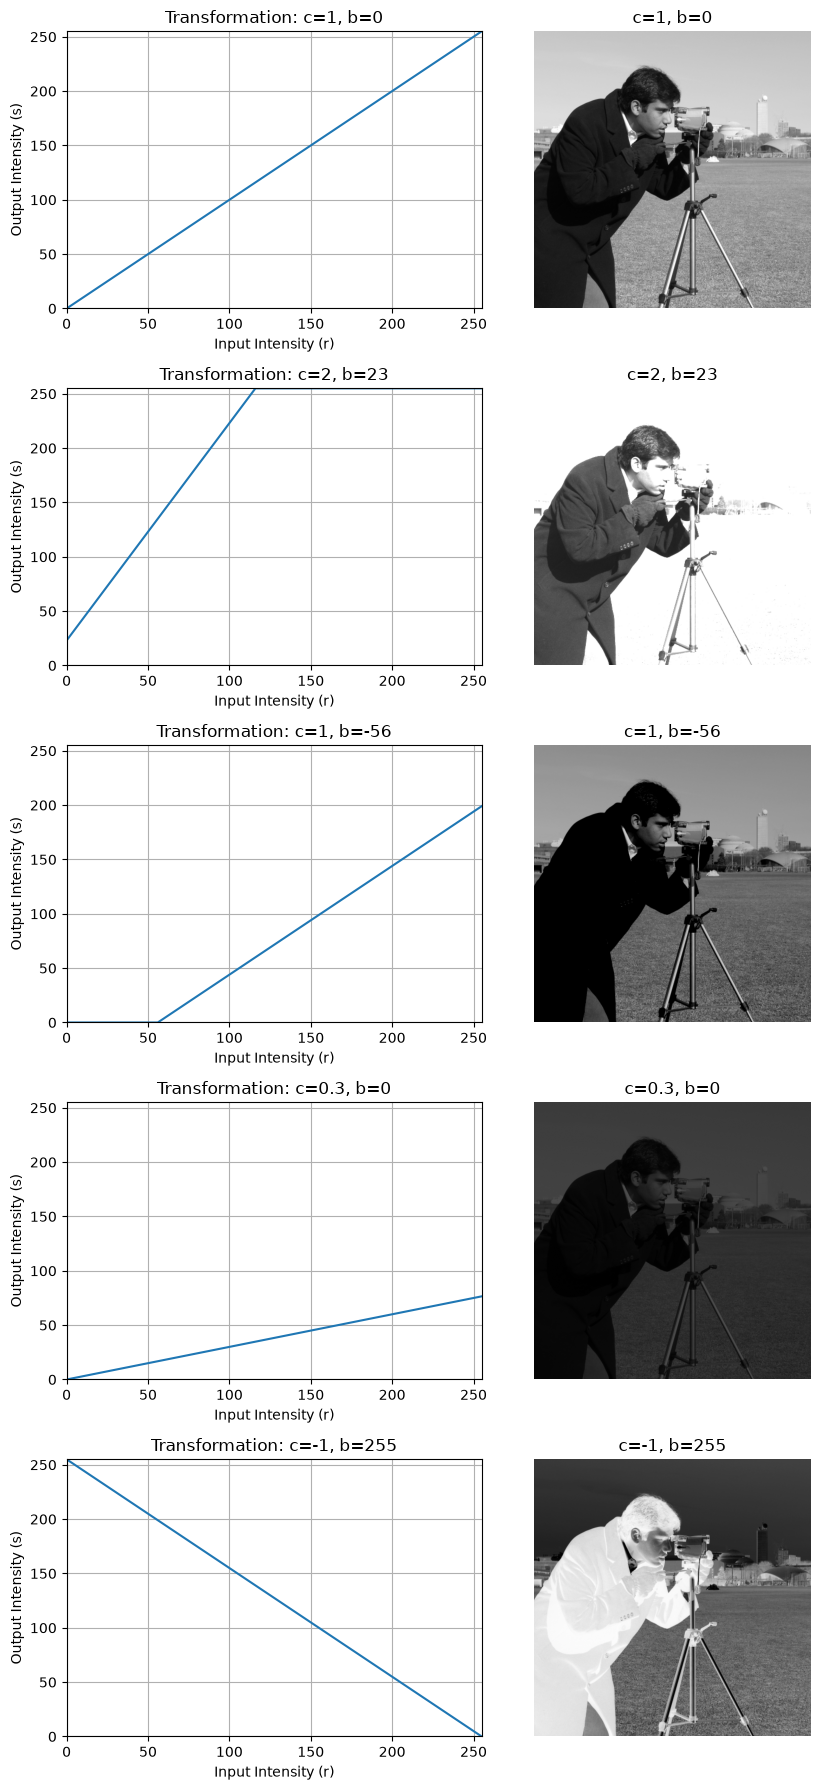

In [1]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

parameters = [
    (1, 0),       # Identity
    (2, 23),      # Brightening and saturation
    (1, -56),     # Darkening
    (0.3, 0),     # Contrast reduction
    (-1, 255)     # Negative
]

r = np.arange(256)

fig, axes = plt.subplots(5, 2, figsize=(9, 18))

for i, (c, b) in enumerate(parameters):
    transformed = np.clip(c * img + b, 0, 255)
    s = np.clip(c * r + b, 0, 255)

    # Transformation function (left)
    axes[i, 0].plot(r, s)
    axes[i, 0].set_title(f"Transformation: c={c}, b={b}")
    axes[i, 0].set_xlim(0, 255)
    axes[i, 0].set_ylim(0, 255)
    axes[i, 0].set_xlabel("Input Intensity (r)")
    axes[i, 0].set_ylabel("Output Intensity (s)")
    axes[i, 0].grid(True)

    # Transformed image (right)
    axes[i, 1].imshow(transformed, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(f"c={c}, b={b}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 2: CONTRAST STRETCHING

Objective: Expand a restricted intensity range to [0, 255].

Formula: s = 255 * (r - r_min) / (r_max - r_min)

Tasks:
 1. Generate a low-contrast image.
 2. Apply min-max contrast stretching.
 3. Examine the intensity transformation function.

Question: What happens if r_max equals r_min?

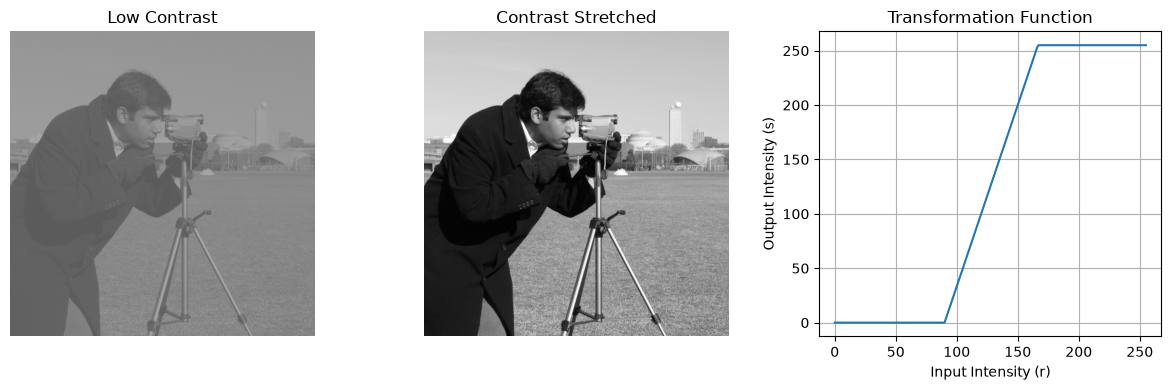

In [2]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

# Simulate reduced contrast
low_contrast = img * 0.3 + 90

r_min, r_max = low_contrast.min(), low_contrast.max()

stretched = 255 * (low_contrast - r_min) / (r_max - r_min)

r = np.linspace(0, 255, 256)
s = np.clip(255 * (r - r_min) / (r_max - r_min), 0, 255)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(low_contrast, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Low Contrast")

axes[1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Contrast Stretched")

axes[2].plot(r, s)
axes[2].set_title("Transformation Function")
axes[2].set_xlabel("Input Intensity (r)")
axes[2].set_ylabel("Output Intensity (s)")
axes[2].grid(True)

for ax in axes[:2]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 3: GRAY-LEVEL SLICING

Objective: Highlight a selected range of pixel intensities.

Tasks:
 1. Select an intensity interval [a, b].
 2. Compare slicing with and without background preservation.
 3. Examine the corresponding transformation functions.

Question: How does background preservation affect image information?

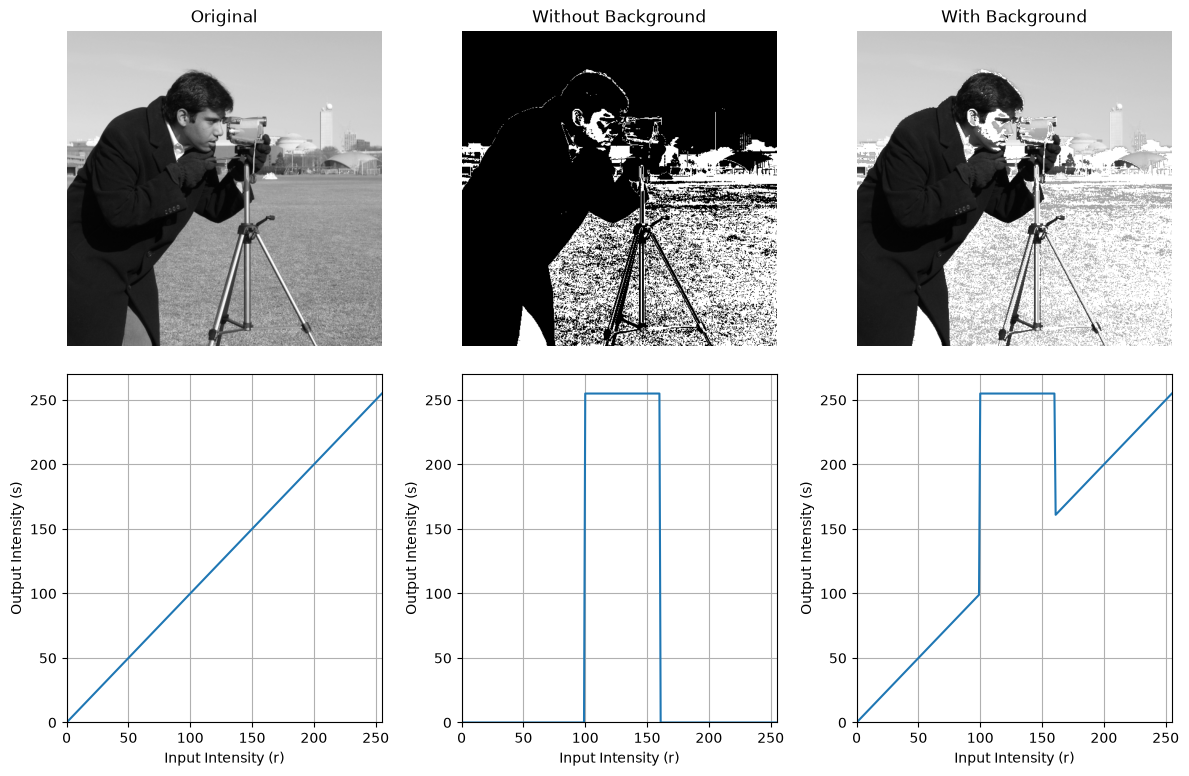

In [3]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera()

a, b = 100, 160
mask = (img >= a) & (img <= b)

# Without background preservation
sliced_binary = np.where(mask, 255, 0).astype(np.uint8)

# With background preservation
sliced_background = np.where(mask, 255, img).astype(np.uint8)

# Transformation functions
r = np.arange(256)
s_binary = np.where((r >= a) & (r <= b), 255, 0)
s_background = np.where((r >= a) & (r <= b), 255, r)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Original image
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

# Without background preservation
axes[0, 1].imshow(sliced_binary, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Without Background")
axes[0, 1].axis("off")

# With background preservation
axes[0, 2].imshow(sliced_background, cmap="gray", vmin=0, vmax=255)
axes[0, 2].set_title("With Background")
axes[0, 2].axis("off")

# Original (identity) transformation
axes[1, 0].plot(r, r)

# Slicing without background
axes[1, 1].plot(r, s_binary)

# Slicing with background
axes[1, 2].plot(r, s_background)

for ax in axes[1]:
    ax.set_xlim(0, 255)
    ax.set_ylim(0, 270)
    ax.set_xlabel("Input Intensity (r)")
    ax.set_ylabel("Output Intensity (s)")
    ax.grid(True)

plt.tight_layout()
plt.show()

### EXPERIMENT 4: GAMMA TRANSFORMATION

Objective: Investigate nonlinear intensity adjustment using s = c*r^gamma.

Tasks:
 1. Apply different gamma values to a grayscale image.
 2. Compare their effects on dark and bright regions.
 3. Examine the corresponding transformation curves.

Question: Why does gamma < 1 brighten an image while gamma > 1 darkens it?


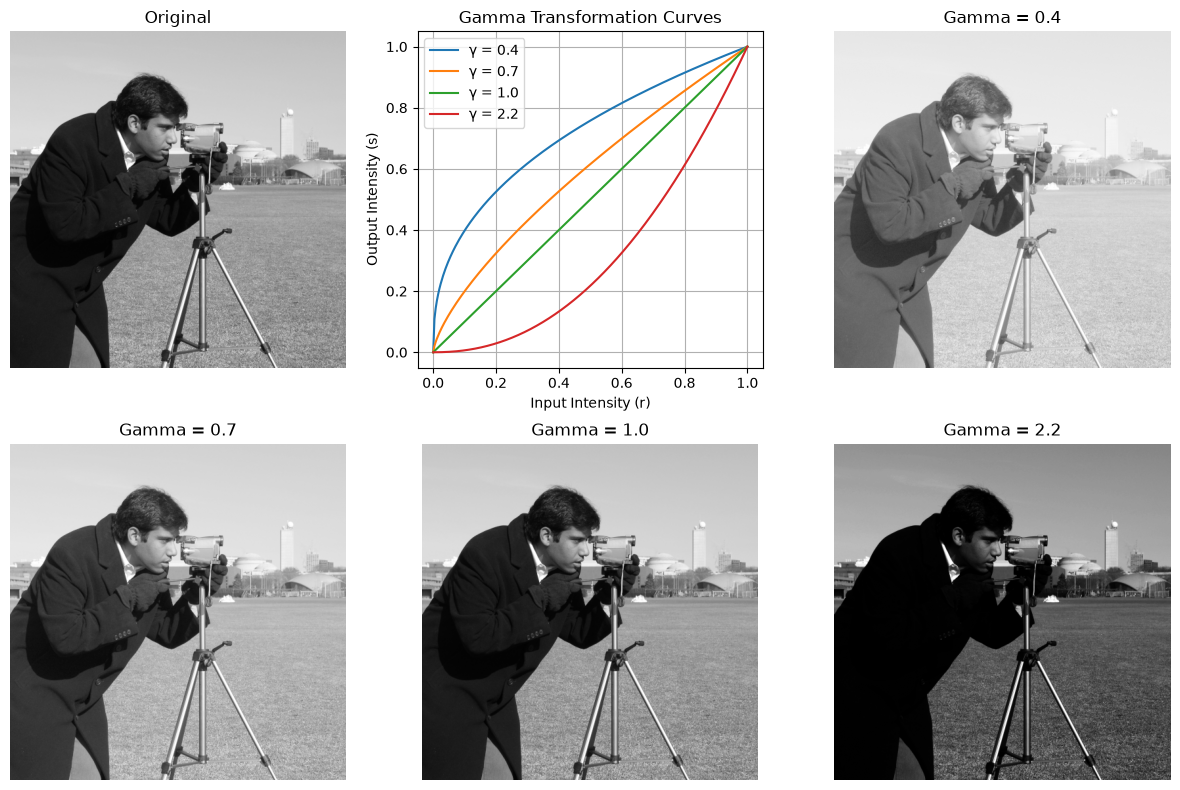

In [4]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float) / 255

gammas = [0.4, 0.7, 1.0, 2.2]
r = np.linspace(0, 1, 256)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Original image
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

# Gamma transformation curves
for gamma in gammas:
    axes[0, 1].plot(r, r**gamma, label=f"γ = {gamma}")

axes[0, 1].set_title("Gamma Transformation Curves")
axes[0, 1].set_xlabel("Input Intensity (r)")
axes[0, 1].set_ylabel("Output Intensity (s)")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Gamma-corrected images
for ax, gamma in zip(
    [axes[0, 2], *axes[1, :]], gammas
):
    transformed = img**gamma

    ax.imshow(transformed, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Gamma = {gamma}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 5: LOGARITHMIC TRANSFORMATION

Objective: Visualize the effect of logarithmic scaling on the Fourier spectrum.

Tasks:
 1. Compute the 2D Fourier transform of an image.
 2. Compare linear and logarithmic magnitude spectra.
 3. Examine the logarithmic transformation curve.

Question: Why are weak frequency components difficult to see without log scaling?

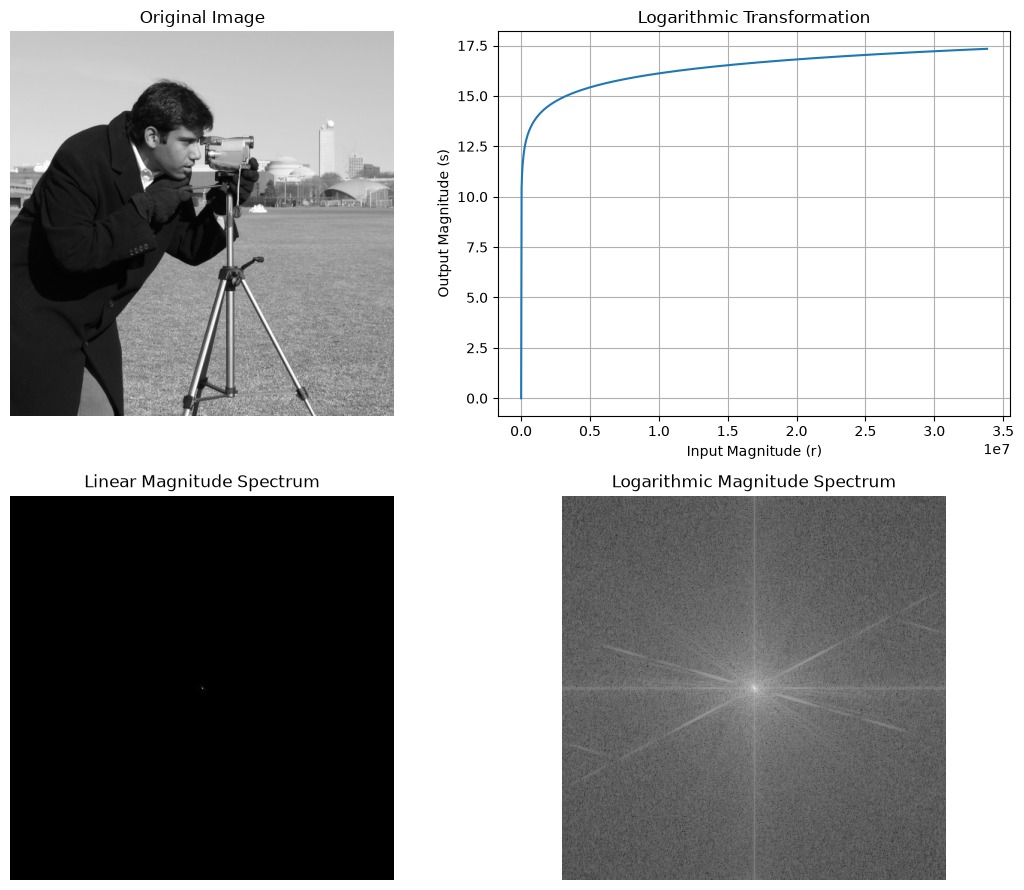

In [5]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

# Compute centered Fourier magnitude spectrum
F = np.fft.fftshift(np.fft.fft2(img))
magnitude = np.abs(F)

# Logarithmic transformation
log_magnitude = np.log1p(magnitude)

# Transformation curve
r = np.linspace(0, magnitude.max(), 1000)
s = np.log1p(r)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# Original image
axes[0, 0].imshow(img, cmap="gray")
axes[0, 0].set_title("Original Image")
axes[0, 0].axis("off")

# Logarithmic transformation curve
axes[0, 1].plot(r, s)
axes[0, 1].set_title("Logarithmic Transformation")
axes[0, 1].set_xlabel("Input Magnitude (r)")
axes[0, 1].set_ylabel("Output Magnitude (s)")
axes[0, 1].grid(True)

# Linear magnitude spectrum
axes[1, 0].imshow(magnitude, cmap="gray")
axes[1, 0].set_title("Linear Magnitude Spectrum")
axes[1, 0].axis("off")

# Logarithmic magnitude spectrum
axes[1, 1].imshow(log_magnitude, cmap="gray")
axes[1, 1].set_title("Logarithmic Magnitude Spectrum")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()